In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('sales_data.csv')
df.head()

,Transaction_ID,Date,Department,Units_Sold,Unit_Price,Discount_Percent,Payment_Method,Region,Customer_Rating,Total_Amount,Final_Amount
0,TXN10000,2023-01-01 00:00:00,Clothing,8,500,5,Cash,South,4,4000,3800.0
1,TXN10001,2023-01-01 01:00:00,Beauty,3,300,10,Credit Card,West,5,900,810.0
2,TXN10002,2023-01-01 02:00:00,Home & Kitchen,8,300,5,UPI,East,3,2400,2280.0
3,TXN10003,2023-01-01 03:00:00,Home & Kitchen,5,500,5,Credit Card,East,4,2500,2375.0
4,TXN10004,2023-01-01 04:00:00,Electronics,1,150,20,Credit Card,East,4,150,120.0


In [4]:
df.tail()

,Transaction_ID,Date,Department,Units_Sold,Unit_Price,Discount_Percent,Payment_Method,Region,Customer_Rating,Total_Amount,Final_Amount
995,TXN10995,2023-02-11 11:00:00,Electronics,1,500,10,Cash,South,5,500,450.0
996,TXN10996,2023-02-11 12:00:00,Beauty,5,150,10,UPI,South,4,750,675.0
997,TXN10997,2023-02-11 13:00:00,Electronics,3,1200,0,Cash,North,4,3600,3600.0
998,TXN10998,2023-02-11 14:00:00,Beauty,1,12000,20,UPI,Central,5,12000,9600.0
999,TXN10999,2023-02-11 15:00:00,Clothing,4,2500,0,Net Banking,South,4,10000,10000.0


In [5]:
print("row and columns: ",df.shape)

row and columns:  (1000, 11)


In [6]:
print("\ncolumn names: ")
print(df.columns.tolist())#tolist list ke formate me change krta h 


column names: 
['Transaction_ID', 'Date', 'Department', 'Units_Sold', 'Unit_Price', 'Discount_Percent', 'Payment_Method', 'Region', 'Customer_Rating', 'Total_Amount', 'Final_Amount']


In [7]:
df.info()# tells us about numeric statistics

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    1000 non-null   object 
 1   Date              1000 non-null   object 
 2   Department        1000 non-null   object 
 3   Units_Sold        1000 non-null   int64  
 4   Unit_Price        1000 non-null   int64  
 5   Discount_Percent  1000 non-null   int64  
 6   Payment_Method    985 non-null    object 
 7   Region            1000 non-null   object 
 8   Customer_Rating   1000 non-null   int64  
 9   Total_Amount      1000 non-null   int64  
 10  Final_Amount      1000 non-null   float64
dtypes: float64(1), int64(5), object(5)
memory usage: 86.1+ KB


In [8]:
# count missing values in eqach column 
df.isnull().sum()

Transaction_ID       0
Date                 0
Department           0
Units_Sold           0
Unit_Price           0
Discount_Percent     0
Payment_Method      15
Region               0
Customer_Rating      0
Total_Amount         0
Final_Amount         0
dtype: int64

In [9]:
#it checks the duplicated rows
print("duplicate rows :", df.duplicated().sum())

duplicate rows : 0


In [10]:
# shows rows where payment method is missing 
df[df["Payment_Method"].isnull()].head()

,Transaction_ID,Date,Department,Units_Sold,Unit_Price,Discount_Percent,Payment_Method,Region,Customer_Rating,Total_Amount,Final_Amount
76,TXN10076,2023-01-04 04:00:00,Books,9,5000,0,NaN,West,3,45000,45000.0
136,TXN10136,2023-01-06 16:00:00,Clothing,2,2500,5,NaN,North,5,5000,4750.0
411,TXN10411,2023-01-18 03:00:00,Beauty,9,1200,10,NaN,Central,3,10800,9720.0
513,TXN10513,2023-01-22 09:00:00,Books,9,2500,5,NaN,North,4,22500,21375.0
521,TXN10521,2023-01-22 17:00:00,Clothing,2,150,0,NaN,Central,3,300,300.0


In [11]:
# 
df["Payment_Method"]=df["Payment_Method"].fillna("unknown")
print("missing values after handling ")
print(df.isnull().sum())

missing values after handling 
Transaction_ID      0
Date                0
Department          0
Units_Sold          0
Unit_Price          0
Discount_Percent    0
Payment_Method      0
Region              0
Customer_Rating     0
Total_Amount        0
Final_Amount        0
dtype: int64


In [12]:
# prepare data column
df['Date']=pd.to_datetime(df['Date'],errors='coerce')
#df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
#errors='coerce' — Agar koi value valid date mein convert nahi ho sakti, toh use NaT(note a time) bana deta hai. NaT ka matlab hai missing ya invalid date.

In [13]:
print("date type :",df["Date"].dtype)
print(df["Date"].head())

date type : datetime64[ns]
0   2023-01-01 00:00:00
1   2023-01-01 01:00:00
2   2023-01-01 02:00:00
3   2023-01-01 03:00:00
4   2023-01-01 04:00:00
Name: Date, dtype: datetime64[ns]


In [14]:
#data range check krna 
print('Date range :',df['Date'].min(),'to',df['Date'].max())

Date range : 2023-01-01 00:00:00 to 2023-02-11 15:00:00


In [15]:
#month column banana
df['Month'] = df['Date'].dt.to_period('M').astype(str)

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    1000 non-null   object        
 1   Date              1000 non-null   datetime64[ns]
 2   Department        1000 non-null   object        
 3   Units_Sold        1000 non-null   int64         
 4   Unit_Price        1000 non-null   int64         
 5   Discount_Percent  1000 non-null   int64         
 6   Payment_Method    1000 non-null   object        
 7   Region            1000 non-null   object        
 8   Customer_Rating   1000 non-null   int64         
 9   Total_Amount      1000 non-null   int64         
 10  Final_Amount      1000 non-null   float64       
 11  Month             1000 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(5), object(5)
memory usage: 93.9+ KB


In [17]:
import pandas as pd

# # Step 1: Convert Date column to datetime
# df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# # Step 2: Create Month column
# df['Month'] = df['Date'].dt.to_period('M').astype(str)

# # Step 3: Check the result
# df[['Date', 'Month']].head()

In [18]:
df[['Date','Month']].head()

,Date,Month
0,2023-01-01 00:00:00,2023-01
1,2023-01-01 01:00:00,2023-01
2,2023-01-01 02:00:00,2023-01
3,2023-01-01 03:00:00,2023-01
4,2023-01-01 04:00:00,2023-01


In [19]:
print('number of transections: ',len(df))

number of transections:  1000


In [20]:
# TOTTAL UNIT SALES

In [21]:
print('total units sold:',df['Units_Sold'].sum())

total units sold: 4986


In [22]:
#sales before discount
print('sales before discount : ₹{:,.2f}'.format(df['Total_Amount'].sum()))
#ctrl+alt+4

sales before discount : ₹14,637,250.00


In [23]:
#sales after discount
print('sales after discount: ₹{:,.2f}'.format(df['Final_Amount'].sum()))

sales after discount: ₹15,333,617.50


In [24]:
#avg final amount per transection 
print("avg final amt per transecton :₹{:,.2f}".format(df['Final_Amount'].mean()))

avg final amt per transecton :₹15,333.62


In [25]:
#isse ye pata chalta h ki ek transection ,e avg kitni ssales AMOUNT  genetrate huyi 

In [26]:
#avg customer rating 
print('avg cutomer rating:',round (df['Customer_Rating'].mean(),2))

avg cutomer rating: 3.69


In [27]:
#mean sabhi customer rating ka avg niklta h 
#round (...,2) result ko decimal ke baad 2 digit tak round karta h 
# agr rating 4,5,3,4 he toh avg rating 4.0 hogi 


In [28]:
# 7 department  wise sales 
# compare sales after discount by department 

Department
Clothing          4218552.5
Electronics       4170150.0
Home & Kitchen    3515595.0
Books             2051957.5
Beauty            1377362.5
Name: Final_Amount, dtype: float64

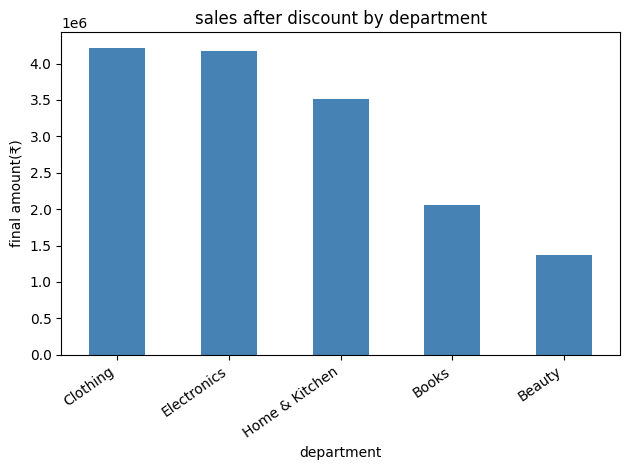

In [29]:
department_sales = df.groupby('Department')['Final_Amount'].sum().sort_values(ascending=False)
display(department_sales)

department_sales.plot(kind='bar',color='steelblue')
plt.title('sales after discount by department')
plt.xlabel("department")
plt.ylabel("final amount(₹)")
plt.xticks(rotation=35,ha='right')
plt.tight_layout()
plt.show()

Region
South      227
North      203
Central    198
East       188
West       184
Name: count, dtype: int64

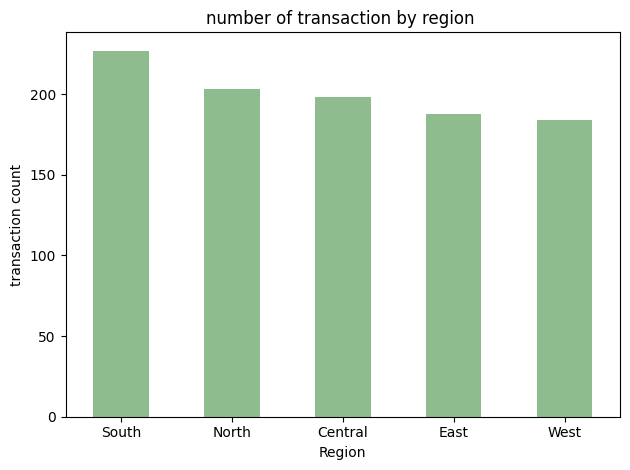

In [30]:
#transaction by region 
region_count = df['Region'].value_counts()
display(region_count)

region_count.plot(kind='bar',color='darkseagreen')
plt.title('number of transaction by region ')
plt.xlabel('Region')
plt.ylabel('transaction count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Payment_Method
Net Banking    217
Cash           198
UPI            196
Debit Card     188
Credit Card    186
unknown         15
Name: count, dtype: int64

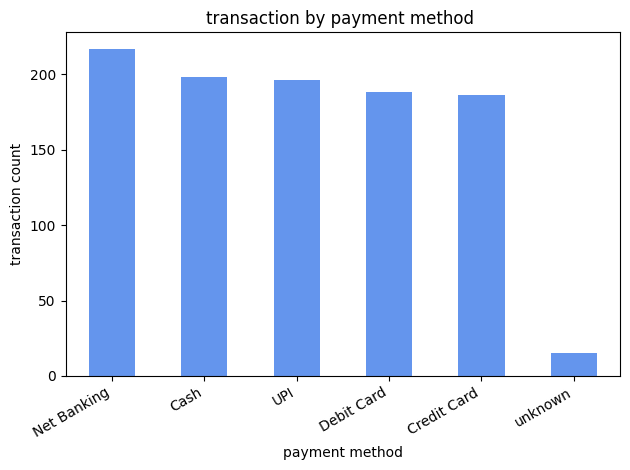

In [31]:
#payment method ananlysis(transaction ki count dikhta )
payment_count = df['Payment_Method'].value_counts()
display(payment_count)

payment_count.plot(kind='bar',color='cornflowerblue')
plt.title('transaction by payment method ')
plt.xlabel('payment method')
plt.ylabel('transaction count')
plt.xticks(rotation=30,ha='right')
plt.tight_layout()
plt.show()


Discount_Percent
0     399
5     185
10    220
15    100
20     96
Name: count, dtype: int64

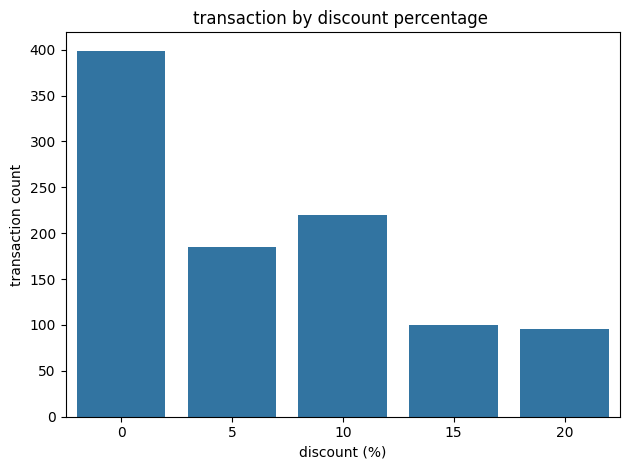

In [32]:
# discount analysis 
# dekho ki har alag discount percentage kistni baar use hua hai
discount_counts = df['Discount_Percent'].value_counts().sort_index()
display(discount_counts)

sns.countplot(data=df,x='Discount_Percent')
plt.title('transaction by discount percentage ')
plt.xlabel('discount (%)')
plt.ylabel('transaction count')
plt.tight_layout()
plt.show()


In [33]:
# 0% discount - 399 transection :399 transaction per koi discount nhi tha 
# 5% discount - 185 transection :185 transaction per 5% discount  tha 
# 10% discount - 220 transection :220 transaction per 10% discount  tha 
# 15% discount - 100 transection :100 transaction per 15% discount  tha 
# 20% discount - 96 transection :96 transaction per 20% discount tha 


#sabse  zada transaction : 0% discount par hua h -399 transaction 
#sabse kam transacton :20% discount par  hui he - 96 transaction 
#10% discount : is category me 220 transaction hui h jo 5%, 15% aur 20% discount  categories se 


Customer_Rating
1     56
2    113
3    212
4    327
5    292
Name: count, dtype: int64

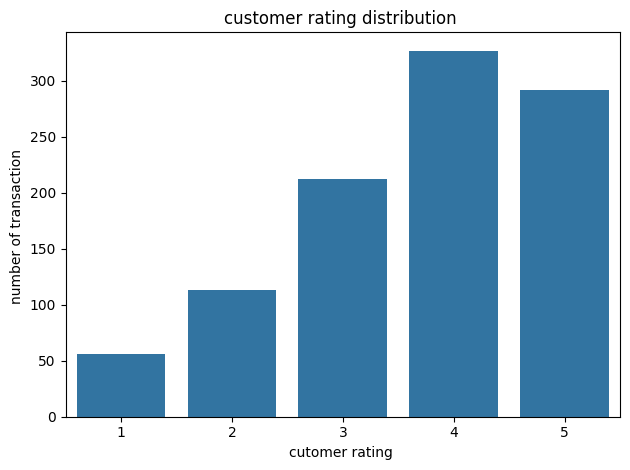

In [34]:
#  customer rating 
rating_count = df['Customer_Rating'].value_counts().sort_index()
display(rating_count)

sns.countplot(data=df,x='Customer_Rating')
plt.title('customer rating distribution ')
plt.xlabel('cutomer rating ')
plt.ylabel('number of transaction ')
plt.tight_layout()
plt.show()




Month
2023-01    12113307.5
2023-02     3220310.0
Name: Final_Amount, dtype: float64

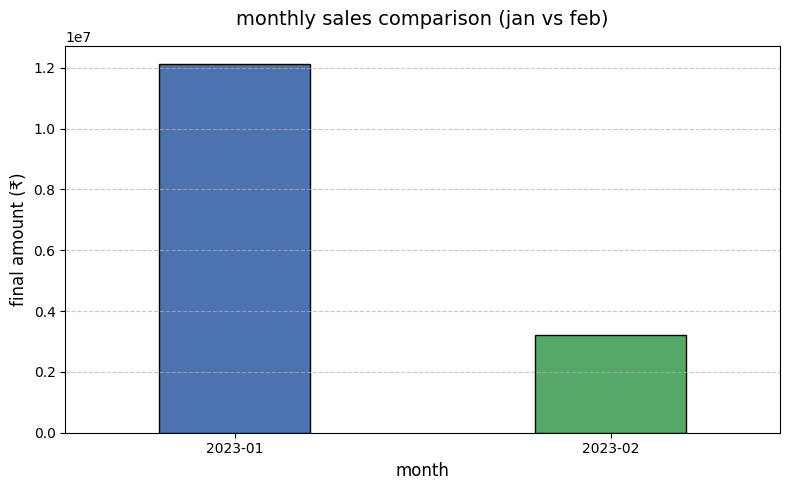

In [35]:
# monthly salaes trend 
monthly_sales =df.groupby('Month')['Final_Amount'].sum()
display(monthly_sales)

plt.figure(figsize=(8,5))

monthly_sales.plot(
    kind='bar',color=['#4C72B0','#55A868' ],width=0.4,
    edgecolor = 'black'
)

plt.title('monthly sales comparison (jan vs feb)', fontsize=14, pad=15)
plt.xlabel('month', fontsize=12)
plt.ylabel('final amount (₹)',fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y',linestyle='--',alpha=0.7)
plt.tight_layout()
plt.show()

In [36]:
print(df['Month'].unique())
print('total months:',df['Month'].nunique())

['2023-01' '2023-02']
total months: 2


In [37]:
df['Month'].unique()

array(['2023-01', '2023-02'], dtype=object)

In [38]:
top_department = department_sales.idxmax()
print(top_department)

print(f'Highest sales department:{top_department}(₹{department_sales.max():,.2f})')

Clothing
Highest sales department:Clothing(₹4,218,552.50)


In [39]:
region_counts = df["Region"].value_counts()
top_region_by_transactions = region_counts.idxmax()

print(f'Most transactions by region:{top_region_by_transactions}({region_counts.max()} transactions)')


# top_region_by_transactions = region_counts.idxmax()

# print(
#     f"Most transactions by region: "
#     f"{top_region_by_transactions} "
#     f"({region_counts.max()} transactions)"
# )

Most transactions by region:South(227 transactions)


In [43]:
payment_counts = df["Payment_Method"].value_counts()
top_payment_method = payment_counts.idxmax()
print(f'Most common payment method: {top_payment_method}({payment_counts.max()} transactions)')

print(f'Average customer rating: {df["Customer_Rating"].mean():.2f} out of 5')


# top_payment_method = payment_counts.idxmax()

# print(
#     f"Most common payment method: "
#     f"{top_payment_method} "
#     f"({payment_counts.max()} transactions)"
# )

Most common payment method: Net Banking(217 transactions)
Average customer rating: 3.69 out of 5


In [41]:
print(f'Average customer rating: {df["Customer_Rating"].mean():.2f} out of 5')

Average customer rating: 3.69 out of 5


In [42]:
department_unit = 

SyntaxError: invalid syntax (1201207141.py, line 1)

In [2]:
!git init

Initialized empty Git repository in C:/Users/Ishika/Desktop/data analyst/.git/


In [6]:
!git commit -m "first commit"


On branch main

Initial commit

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.ipynb_checkpoints/
	EDA/
	Untitled.ipynb
	health.ipynb
	matplotlib/
	numpy/
	pandas/
	sales_data.csv
	salesdata2026.ipynb
	seaborn/

nothing added to commit but untracked files present (use "git add" to track)


In [7]:
!git branch -M main



In [8]:
!git add salesdata2026.ipynb sales_data.csv


In [10]:
!git push -u origin main

error: src refspec main does not match any
error: failed to push some refs to 'https://github.com/ishikaax05/EDA-PROJECT.git'
